In [1]:
import pandas as pd
import numpy as np
from mlxtend.preprocessing import TransactionEncoder
import matplotlib.pyplot as plt

In [82]:
data = pd.read_csv('bread_basket.xls')
print(data.shape)
data.head(10)

(20507, 5)


,Transaction,Item,date_time,period_day,weekday_weekend
0,1,Bread,30-10-2016 09:58,morning,weekend
1,2,Scandinavian,30-10-2016 10:05,morning,weekend
2,2,Scandinavian,30-10-2016 10:05,morning,weekend
3,3,Hot chocolate,30-10-2016 10:07,morning,weekend
4,3,Jam,30-10-2016 10:07,morning,weekend
5,3,Cookies,30-10-2016 10:07,morning,weekend
6,4,Muffin,30-10-2016 10:08,morning,weekend
7,5,Coffee,30-10-2016 10:13,morning,weekend
8,5,Pastry,30-10-2016 10:13,morning,weekend
9,5,Bread,30-10-2016 10:13,morning,weekend


In [59]:
data.isna().sum()

Transaction        0
Item               0
date_time          0
period_day         0
weekday_weekend    0
dtype: int64

In [61]:
data.info()

<class 'pandas.DataFrame'>
RangeIndex: 20507 entries, 0 to 20506
Data columns (total 5 columns):
 #   Column           Non-Null Count  Dtype
---  ------           --------------  -----
 0   Transaction      20507 non-null  int64
 1   Item             20507 non-null  str  
 2   date_time        20507 non-null  str  
 3   period_day       20507 non-null  str  
 4   weekday_weekend  20507 non-null  str  
dtypes: int64(1), str(4)
memory usage: 801.2 KB


In [64]:
data.nunique()

Transaction        9465
Item                 94
date_time          9182
period_day            4
weekday_weekend       2
dtype: int64

In [65]:
data['period_day'].unique()

<StringArray>
['morning', 'afternoon', 'evening', 'night']
Length: 4, dtype: str

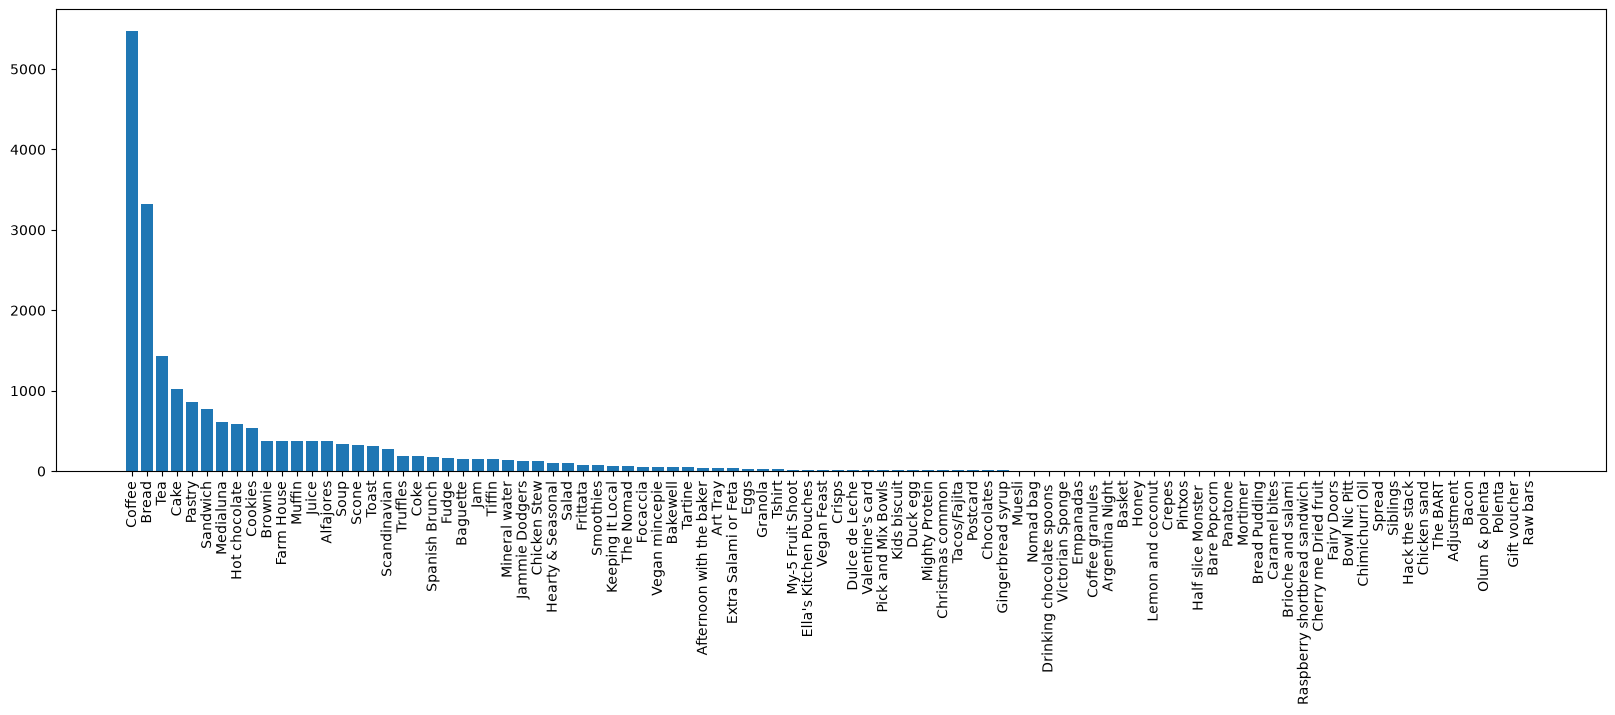

In [51]:
counts = data['Item'].value_counts()
plt.figure(figsize=(20, 6))
plt.bar(counts.index, counts.values)
plt.xticks(rotation=90)
plt.show()



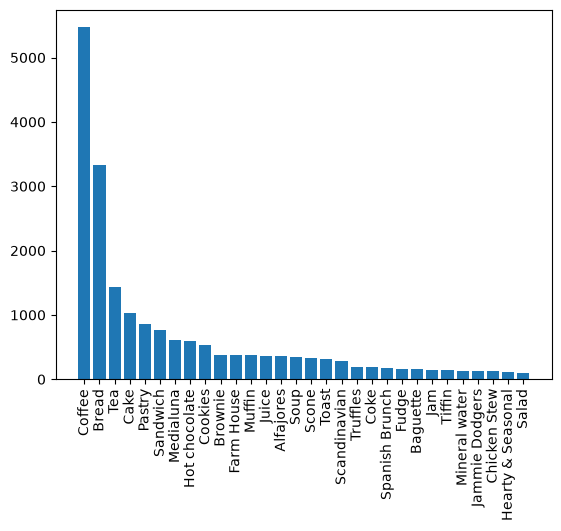

In [55]:
#plt.figure(figsize=(20, 6))
plt.bar(counts.index[:30], counts.values[:30])
plt.xticks(rotation=90)
plt.show()

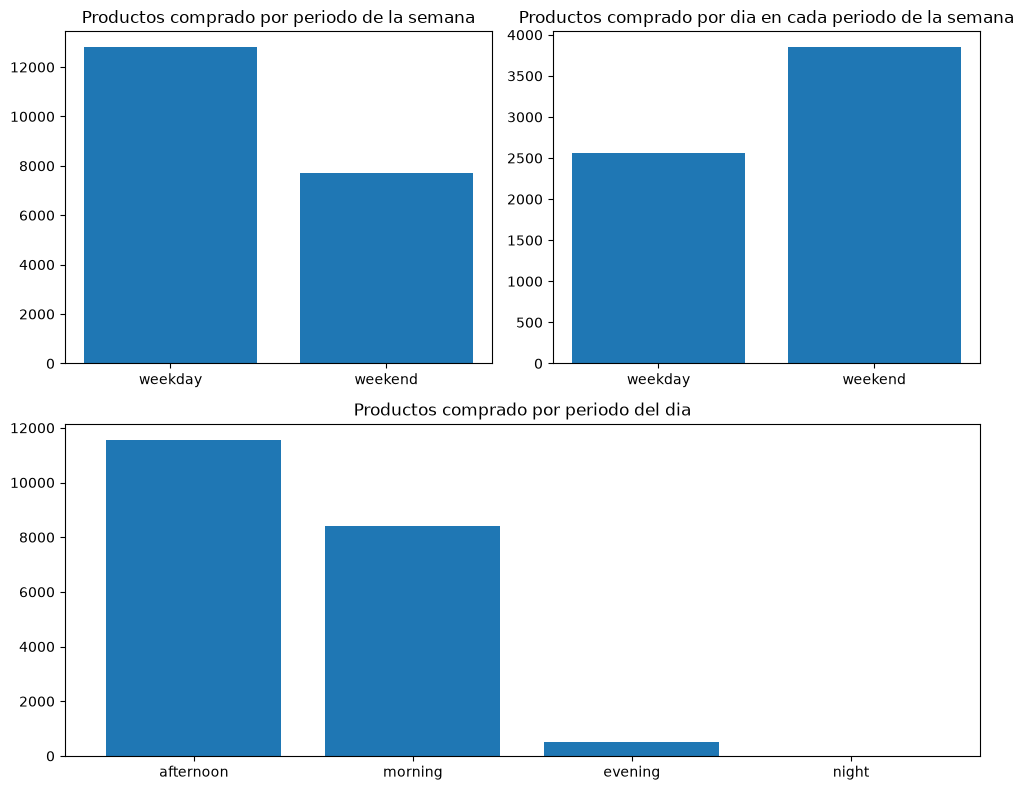

In [103]:
weekend_counts = data['weekday_weekend'].value_counts()
weekend_counts_norm = weekend_counts.astype(float)
weekend_counts_norm['weekend'] = weekend_counts_norm['weekend'] / 2
weekend_counts_norm['weekday'] = weekend_counts_norm['weekday'] / 5

fig, ax = plt.subplot_mosaic(
    [['left', 'right'],
     ['bottom', 'bottom']],
    figsize=(10, 8),
)

ax['left'].bar(weekend_counts.index, weekend_counts.values)
ax['left'].tick_params(axis='x', rotation=0)
ax['left'].set_title('Productos comprado por periodo de la semana')

ax['right'].bar(weekend_counts_norm.index, weekend_counts_norm.values)
ax['right'].tick_params(axis='x', rotation=0)
ax['right'].set_title('Productos comprado por dia en cada periodo de la semana')

period_counts=data['period_day'].value_counts()
ax['bottom'].bar(period_counts.index, period_counts.values)
ax['bottom'].tick_params(axis='x', rotation=0)
ax['bottom'].set_title('Productos comprado por periodo del dia')

plt.tight_layout()
plt.show()

In [81]:
transaction = data.groupby('Transaction').agg(
    Items=('Item', list),
    date_time=('date_time','first'),
    period_day=('period_day','first'),
    weekday_weekend=('weekday_weekend','first')
)

print(transaction.shape)
transaction.head()

(9465, 4)


,Items,date_time,period_day,weekday_weekend
Transaction,,,,
1,[Bread],30-10-2016 09:58,morning,weekend
2,"[Scandinavian, Scandinavian]",30-10-2016 10:05,morning,weekend
3,"[Hot chocolate, Jam, Cookies]",30-10-2016 10:07,morning,weekend
4,[Muffin],30-10-2016 10:08,morning,weekend
5,"[Coffee, Pastry, Bread]",30-10-2016 10:13,morning,weekend


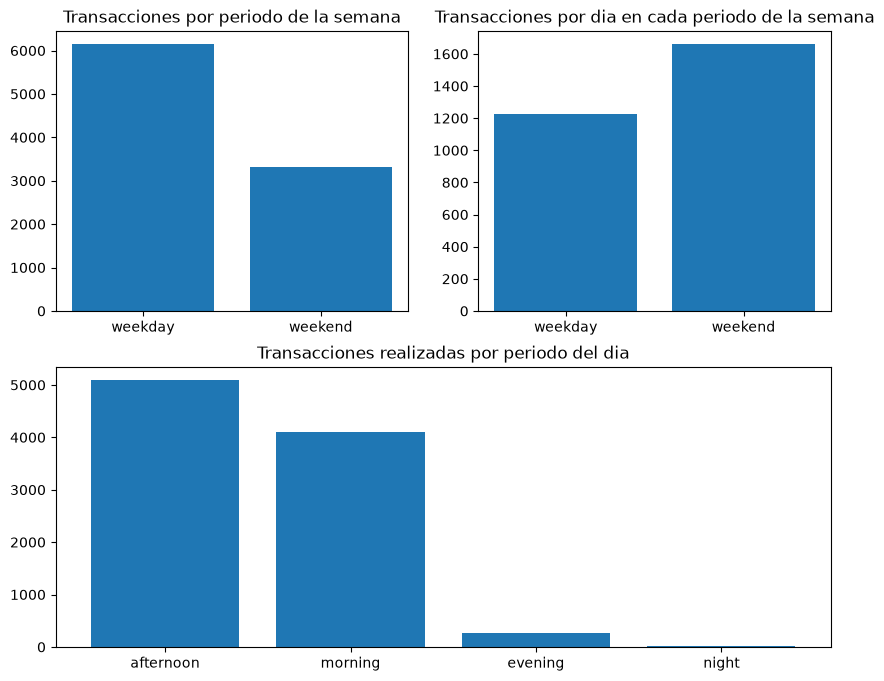

In [105]:
week_transactions = transaction['weekday_weekend'].value_counts()
week_transactions_norm = week_transactions.astype(float)
week_transactions_norm['weekend'] = week_transactions_norm['weekend'] / 2
week_transactions_norm['weekday'] = week_transactions_norm['weekday'] / 5

fig, ax = plt.subplot_mosaic(
    [['left', 'right'],
     ['bottom', 'bottom']],
    figsize=(10, 8),
)

ax['left'].bar(week_transactions.index, week_transactions.values)
ax['left'].tick_params(axis='x')
ax['left'].set_title('Transacciones por periodo de la semana')

ax['right'].bar(week_transactions_norm.index, week_transactions_norm.values)
ax['right'].tick_params(axis='x')
ax['right'].set_title('Transacciones por dia en cada periodo de la semana')


period_counts=transaction['period_day'].value_counts()
ax['bottom'].bar(period_counts.index, period_counts.values)
ax['bottom'].tick_params(axis='x')
ax['bottom'].set_title('Transacciones realizadas por periodo del dia')

plt.show() 

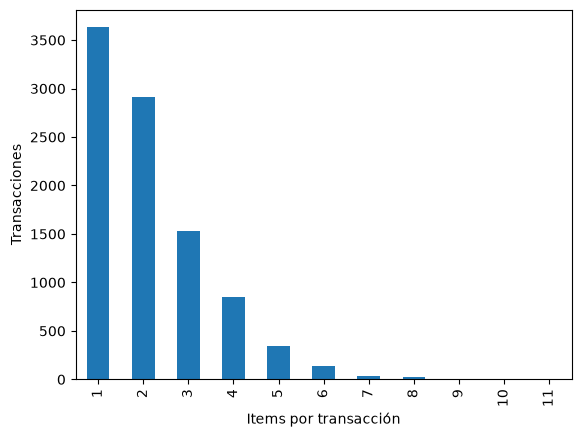

In [117]:

n_items = transaction['Items'].str.len()

n_items.value_counts().sort_index().plot(kind='bar')
plt.xlabel('Items por transacción')
plt.ylabel('Transacciones')
plt.show()

In [118]:
te = TransactionEncoder()
te_ary = te.fit(transaction['Items']).transform(transaction['Items'])
df = pd.DataFrame(te_ary, columns=te.columns_)
df

,Adjustment,Afternoon with the baker,Alfajores,Argentina Night,Art Tray,Bacon,Baguette,Bakewell,Bare Popcorn,Basket,...,The BART,The Nomad,Tiffin,Toast,Truffles,Tshirt,Valentine's card,Vegan Feast,Vegan mincepie,Victorian Sponge
0,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
1,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
2,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
3,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
4,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9460,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
9461,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,True,False,False,False,False,False
9462,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
9463,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
